# Step 9 — Effective Number of Independent Tests

This notebook demonstrates the calculation of effective independent
test counts for genetic variants and correlated phenotypes.

## SNP analysis
Uses an existing public demonstration PLINK BED/BIM/FAM dataset.
A small chromosome 22 SNP subset is selected to demonstrate LD
correlation, eigenvalue decomposition, and an effective test estimate.

This subset-based calculation is NOT equivalent to the original
genome-wide KGGSEE/GEC analysis.

## Phenotype analysis
Generates fully synthetic imaging and glycemic phenotypes with
deliberately correlated structures.

Pearson correlation matrices and Li–Ji (2005) eigenvalue-based
effective test counts are calculated for:
- Six simulated imaging-derived phenotypes
- Six imaging phenotypes plus T2D, fasting glucose and HbA1c

## Original study reference
- Effective SNP tests: 768,377.22 (KGGSEE/GEC)
- 37 imaging phenotypes: 23 effective tests
- 40 phenotypes: 25 effective tests
- Study-wide threshold: approximately 2.6e-9

Demonstration estimates are not expected to reproduce these values.
No private phenotype or individual-level genotype data are exported.


In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "Demo_data").is_dir():
    raise RuntimeError("Start Jupyter in the GitHub root")

GENO_DIR = ROOT / "Demo_data/1-3.Sample_genotype"
OUT = ROOT / "Outputs/Step9_Independent_Test_Counts"
OUT.mkdir(parents=True, exist_ok=True)

# Reproducible demonstration settings
SEED = 20261103
N_SYNTHETIC = 100
ALPHA = 0.05

# SNP demonstration settings
SNP_SCAN_LIMIT = 600
SNP_KEEP_MAX = 60
MIN_MAF = 0.05
MIN_CALL_RATE = 0.90

# Li–Ji (2005) effective test count
def li_ji_me(eigenvalues):
    x = np.clip(np.asarray(eigenvalues, float), 0, None)
    near = np.isclose(x, np.rint(x), atol=1e-10)
    x[near] = np.rint(x[near])
    raw = float(np.sum(
        (x >= 1).astype(float) + (x - np.floor(x))
    ))
    return raw, int(np.floor(raw + 1e-9))

# Li et al. (2012)-style eigenvalue reduction.
# Demo subset only, not full KGGSEE/GEC.
def li2012_demo_me(eigenvalues):
    x = np.clip(np.asarray(eigenvalues, float), 0, None)
    return float(len(x) - np.maximum(x - 1, 0).sum())

def heatmap(corr, title, filename, step=1):
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(
        corr.to_numpy(),
        vmin=-1, vmax=1,
        cmap="coolwarm"
    )
    idx = np.arange(0, len(corr), step)
    ax.set_xticks(
        idx, [corr.columns[i] for i in idx],
        rotation=90, fontsize=7
    )
    ax.set_yticks(
        idx, [corr.index[i] for i in idx],
        fontsize=7
    )
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label="Pearson r")
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=180)
    plt.show()
    plt.close(fig)

print("Demo configuration loaded")


Demo configuration loaded


Synthetic_IDPs: N=6, Meff=5.000, integer=5


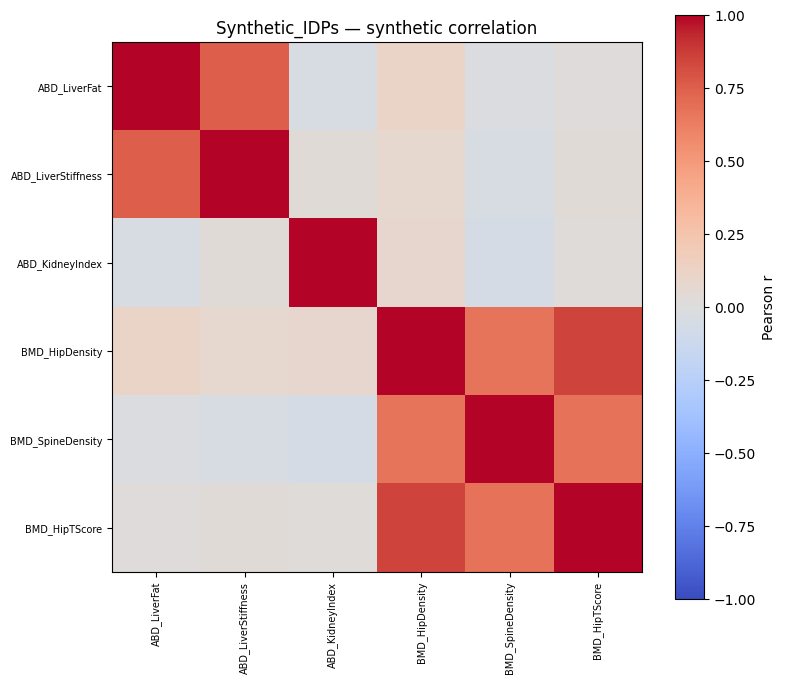

Synthetic_IDPs_plus_glycemic: N=9, Meff=6.000, integer=6


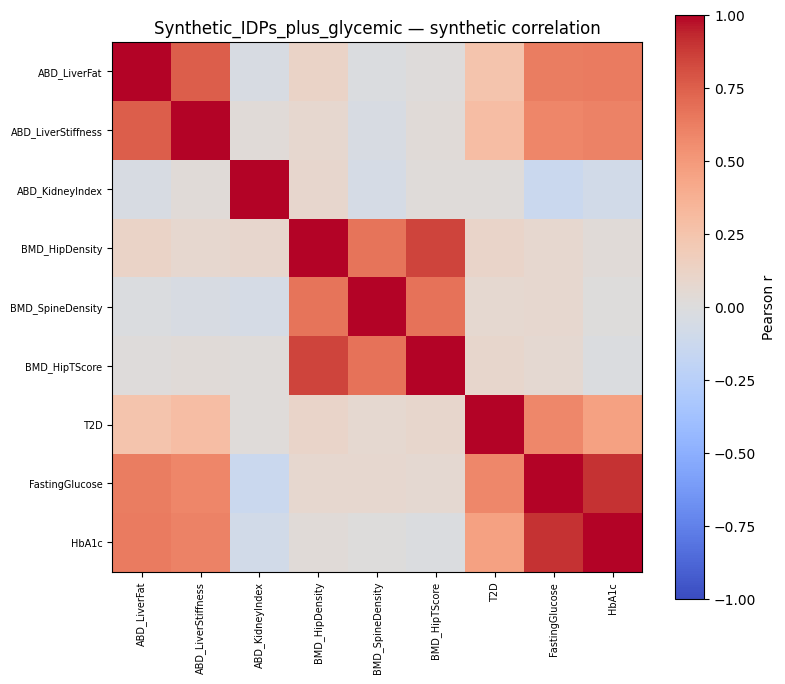

In [2]:

# ============================================================
# SYNTHETIC PHENOTYPES
# None of these values originate from real participants.
# ============================================================

rng = np.random.default_rng(SEED)
n = N_SYNTHETIC

metabolic = rng.normal(size=n)
bone = rng.normal(size=n)
kidney = rng.normal(size=n)
glycemic = 0.65 * metabolic + 0.76 * rng.normal(size=n)

p_t2d = 1 / (1 + np.exp(-(-1.3 + 1.1 * glycemic)))
t2d = rng.binomial(1, p_t2d, size=n)

pheno = pd.DataFrame({
    "Demo_ID": [f"SYN_{i:03d}" for i in range(1, n+1)],
    "ABD_LiverFat":
        1.1 * metabolic + 0.45 * rng.normal(size=n),
    "ABD_LiverStiffness":
        0.8 * metabolic + 0.60 * rng.normal(size=n),
    "ABD_KidneyIndex":
        kidney + 0.40 * rng.normal(size=n),
    "BMD_HipDensity":
        0.9 * bone + 0.35 * rng.normal(size=n),
    "BMD_SpineDensity":
        0.75 * bone + 0.55 * rng.normal(size=n),
    "BMD_HipTScore":
        bone + 0.30 * rng.normal(size=n),
    "T2D": t2d,
    "FastingGlucose":
        95 + 17*glycemic + 13*t2d
        + 6*rng.normal(size=n),
    "HbA1c":
        5.5 + 0.55*glycemic + 0.22*t2d
        + 0.2*rng.normal(size=n),
})

pheno.to_csv(
    OUT / "synthetic_phenotypes.csv", index=False
)

idps = [
    c for c in pheno.columns
    if c.startswith(("ABD_", "BMD_"))
]
all_traits = idps + ["T2D", "FastingGlucose", "HbA1c"]

phenotype_rows = []

for name, cols in [
    ("Synthetic_IDPs", idps),
    ("Synthetic_IDPs_plus_glycemic", all_traits),
]:
    corr = pheno[cols].corr(method="pearson")
    eig = np.linalg.eigvalsh(corr.to_numpy())

    if eig.min() < -1e-8:
        raise ValueError("Invalid phenotype correlation")

    me_raw, me_integer = li_ji_me(eig)

    corr.to_csv(OUT / f"{name}_correlation.csv")
    pd.DataFrame({
        "Eigenvalue": sorted(eig, reverse=True)
    }).to_csv(
        OUT / f"{name}_eigenvalues.csv",
        index=False
    )

    phenotype_rows.append({
        "Dataset": name,
        "N_tests": len(cols),
        "LiJi_Meff_raw": me_raw,
        "LiJi_Meff_floor": me_integer,
    })

    print(
        f"{name}: N={len(cols)}, "
        f"Meff={me_raw:.3f}, integer={me_integer}"
    )

    heatmap(
        corr,
        f"{name} — synthetic correlation",
        f"{name}_heatmap.png",
    )

phenotype_results = pd.DataFrame(phenotype_rows)
phenotype_results.to_csv(
    OUT / "phenotype_effective_tests.csv",
    index=False
)


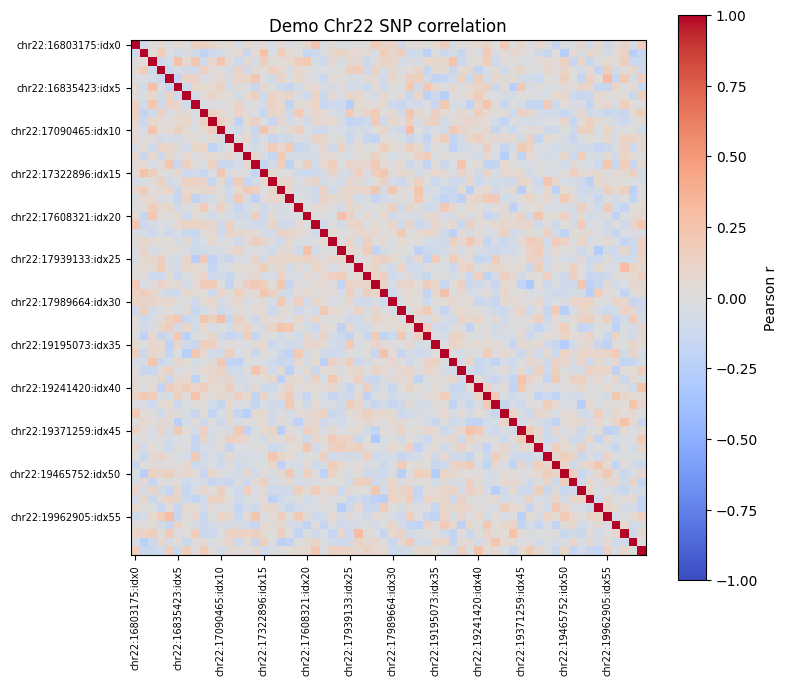

Input: Demo_data/1-3.Sample_genotype/demo_chr22.bed
Genotype N: 100
Selected SNPs: 60
Demo SNP effective tests: 40.784


In [3]:

# ============================================================
# CHR22 DEMO GENOTYPE
# Read only selected SNPs from variant-major PLINK BED.
# ============================================================

bed_files = [
    p for p in GENO_DIR.rglob("*.bed")
    if p.with_suffix(".bim").is_file()
    and p.with_suffix(".fam").is_file()
]
if not bed_files:
    raise FileNotFoundError(
        f"No BED/BIM/FAM dataset under {GENO_DIR}"
    )

bed = sorted(
    bed_files,
    key=lambda p: ("22" not in p.stem, str(p))
)[0]
bim = bed.with_suffix(".bim")
fam = bed.with_suffix(".fam")

with fam.open() as f:
    n_samples = sum(bool(line.strip()) for line in f)

if n_samples < 5:
    raise ValueError("Insufficient genotype samples")

# The SNP index is the variant's actual row in BIM/BED.
candidates = []
with bim.open() as f:
    for i, line in enumerate(f):
        parts = line.split()
        if len(parts) < 4:
            raise ValueError(f"Invalid BIM row {i+1}")
        chrom = parts[0].lower().removeprefix("chr")
        if chrom == "22":
            candidates.append((i, parts[3]))
            if len(candidates) >= SNP_SCAN_LIMIT:
                break

if not candidates:
    raise ValueError("No chromosome 22 variants found")

bytes_per_variant = (n_samples + 3) // 4
sample_idx = np.arange(n_samples)
dosage_map = np.array([0.0, np.nan, 1.0, 2.0])

columns = []
labels = []
variant_rows = []

with bed.open("rb") as f:
    header = f.read(3)
    if header != bytes([0x6c, 0x1b, 0x01]):
        raise ValueError("Expected SNP-major PLINK BED")

    for index, position in candidates:
        f.seek(3 + index * bytes_per_variant)
        buffer = np.frombuffer(
            f.read(bytes_per_variant),
            dtype=np.uint8
        )
        if len(buffer) != bytes_per_variant:
            raise EOFError("Truncated BED")

        bits = (
            buffer[sample_idx // 4]
            >> (2 * (sample_idx % 4))
        ) & 3

        dosage = dosage_map[bits]
        observed = dosage[np.isfinite(dosage)]

        if len(observed) < 5:
            continue

        call_rate = len(observed) / n_samples
        freq = observed.mean() / 2
        maf = min(freq, 1 - freq)

        if call_rate < MIN_CALL_RATE or maf <= MIN_MAF:
            continue

        dosage = np.where(
            np.isfinite(dosage),
            dosage,
            observed.mean()
        )
        if dosage.std() < 1e-10:
            continue

        label = f"chr22:{position}:idx{index}"
        labels.append(label)
        columns.append(dosage)
        variant_rows.append({
            "Variant": label,
            "Position": position,
            "MAF": maf,
            "CallRate": call_rate,
        })

        if len(columns) >= SNP_KEEP_MAX:
            break

if len(columns) < 2:
    raise ValueError("Too few valid demo SNPs")

G = np.column_stack(columns)
corr_snp = pd.DataFrame(
    np.corrcoef(G, rowvar=False),
    index=labels,
    columns=labels,
)
eig_snp = np.linalg.eigvalsh(corr_snp.to_numpy())

if eig_snp.min() < -1e-8:
    raise ValueError("SNP correlation matrix is not PSD")

snp_me = li2012_demo_me(eig_snp)

corr_snp.to_csv(
    OUT / "demo_chr22_snp_correlation.csv"
)
pd.DataFrame(variant_rows).to_csv(
    OUT / "demo_chr22_selected_SNPs.csv",
    index=False
)
pd.DataFrame({
    "Eigenvalue": sorted(eig_snp, reverse=True)
}).to_csv(
    OUT / "demo_chr22_snp_eigenvalues.csv",
    index=False
)

heatmap(
    corr_snp,
    "Demo Chr22 SNP correlation",
    "demo_chr22_snp_heatmap.png",
    step=max(1, len(labels)//12),
)

print("Input:", bed.relative_to(ROOT))
print("Genotype N:", n_samples)
print("Selected SNPs:", len(labels))
print("Demo SNP effective tests:", round(snp_me, 3))


In [4]:

# ============================================================
# DEMONSTRATION RESULTS
# ============================================================

summary = pd.DataFrame([
    {
        "Analysis": "Demo SNP (Chr22 subset)",
        "N_tests": len(labels),
        "Meff": snp_me,
    },
    {
        "Analysis": "Synthetic IDPs",
        "N_tests": len(idps),
        "Meff": phenotype_results.loc[0, "LiJi_Meff_floor"],
    },
    {
        "Analysis": "Synthetic IDPs + glycemic",
        "N_tests": len(all_traits),
        "Meff": phenotype_results.loc[1, "LiJi_Meff_floor"],
    },
])

summary.to_csv(
    OUT / "effective_test_summary.csv", index=False
)

demo_threshold = (
    ALPHA / (snp_me * summary.loc[2, "Meff"])
)

print(summary.to_string(index=False))
print(f"\\nDemo-only threshold: {demo_threshold:.3g}")
print("Study threshold: approximately 2.6e-9")
print("These are distinct demonstration and study results.")
print("Output:", OUT.relative_to(ROOT))


                 Analysis  N_tests      Meff
  Demo SNP (Chr22 subset)       60 40.783577
           Synthetic IDPs        6  5.000000
Synthetic IDPs + glycemic        9  6.000000
\nDemo-only threshold: 0.000204
Study threshold: approximately 2.6e-9
These are distinct demonstration and study results.
Output: Outputs/Step9_Independent_Test_Counts
